# 02 — Autoencoders & Variational Autoencoders on 8×8 digits

This notebook builds a plain **autoencoder (AE)** and a **variational autoencoder (VAE)** in PyTorch and trains both on scikit-learn's 8×8 handwritten digits (1,797 images, 64 pixels each). The two models use the same layer sizes, so any difference between them comes from the objective.

| | Autoencoder | VAE |
|---|---|---|
| Encoder output | a point $z$ | a distribution $q(z\mid x)=\mathcal N(\mu, \sigma^2)$ |
| Loss | reconstruction (MSE) | reconstruction (BCE) + $\beta\cdot$KL$(q(z\mid x)\,\|\,\mathcal N(0, I))$ |
| Latent space | wherever the optimiser puts it | pulled toward a standard normal |
| Can generate new samples? | not reliably | yes: sample $z\sim\mathcal N(0,I)$ and decode |

**Roadmap**
1. Data and a quick look at it
2. Models
3. Training and loss curves
4. Reconstructions: how good, and where they fail
5. The latent space: PCA / t-SNE, per-dimension statistics, KL per dimension
6. Linear probe: how much label information survives in 8 numbers?
7. Generation: sampling from the prior
8. Latent interpolation
9. Denoising (and a denoising AE)
10. How big should the latent be? AE vs PCA
11. A 2-D VAE: the latent manifold

In [1]:
"""
02 - Autoencoder on a 8x8 handwritten digits.
"""
# Pytorch
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

# Scikit learn
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "lines.linewidth": 2,
})
# Fixed colours so a model always has the same colour in every plot
C_AE, C_VAE, C_BASE, C_DAE = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6"

In [2]:
# Setting the PyTorch seed
SEED = 373
torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print("device:", device)

device: mps


## 1. Data

Each image is an 8×8 grid of integers in $[0, 16]$. We divide by 16 so pixels lie in $[0, 1]$. That range matches the decoder's final `Sigmoid` and lets us use binary cross-entropy for the VAE.

The labels `y` play **no part in training**. Autoencoders are unsupervised. We keep the labels only to *evaluate* the latent space later (colouring plots and running a linear probe).

In [3]:
# 1. Data
# Loading the dataset from load_digts | 1797 images
digits = load_digits()
X = torch.tensor(digits.data / 16.0, dtype=torch.float32)
y = digits.target                                           # y in autoencoder is not part of the loss

X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
train_dl = DataLoader(TensorDataset(X_tr), batch_size=64, shuffle=True)
val_dl = DataLoader(TensorDataset(X_va), batch_size=512)

print(f"X: {tuple(X.shape)}  |  train {len(X_tr)}  |  val {len(X_va)}")

X: (1797, 64)  |  train 1437  |  val 360


In [4]:
X

tensor([[0.0000, 0.0000, 0.3125,  ..., 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000,  ..., 0.6250, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000,  ..., 1.0000, 0.5625, 0.0000],
        ...,
        [0.0000, 0.0000, 0.0625,  ..., 0.3750, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.1250,  ..., 0.7500, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.6250,  ..., 0.7500, 0.0625, 0.0000]])

In [5]:
digits.data[0]

array([ 0.,  0.,  5., 13.,  9.,  1.,  0.,  0.,  0.,  0., 13., 15., 10.,
       15.,  5.,  0.,  0.,  3., 15.,  2.,  0., 11.,  8.,  0.,  0.,  4.,
       12.,  0.,  0.,  8.,  8.,  0.,  0.,  5.,  8.,  0.,  0.,  9.,  8.,
        0.,  0.,  4., 11.,  0.,  1., 12.,  7.,  0.,  0.,  2., 14.,  5.,
       10., 12.,  0.,  0.,  0.,  0.,  6., 13., 10.,  0.,  0.,  0.])

### 1.1 What the raw vector looks like as an image
A row of `X` is just the 8×8 image flattened row by row. Reshaping it back gives the picture.

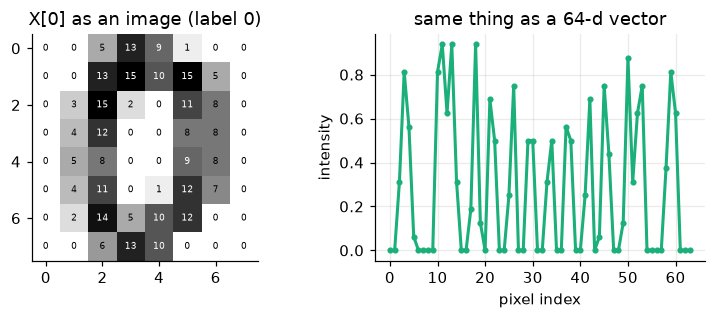

In [6]:
def show_digits(imgs, nrows, ncols, titles=None, row_labels=None, size=0.9, suptitle=None, cmap="gray_r"):
    """Plot a batch of flattened 8x8 images (tensor or array, shape [n, 64]) on a grid."""
    imgs = imgs.detach().cpu().numpy() if torch.is_tensor(imgs) else np.asarray(imgs)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size), squeeze=False)
    for i, ax in enumerate(axes.flat):
        ax.axis("off")
        if i < len(imgs):
            ax.imshow(imgs[i].reshape(8, 8), cmap=cmap, vmin=0, vmax=1)
            if titles is not None:
                ax.set_title(titles[i], fontsize=8)
    if row_labels is not None:
        for r, lab in enumerate(row_labels):
            axes[r, 0].text(-1.5, 3.5, lab, ha="right", va="center", fontsize=9)
    if suptitle:
        fig.suptitle(suptitle, y=1.02)
    plt.tight_layout()
    plt.show()

fig, axes = plt.subplots(1, 2, figsize=(7, 3))
axes[0].imshow(X[0].reshape(8, 8), cmap="gray_r")
axes[0].set_title(f"X[0] as an image (label {y[0]})"); axes[0].grid(False)
for (r, c), v in np.ndenumerate(digits.data[0].reshape(8, 8)):
    axes[0].text(c, r, int(v), ha="center", va="center", fontsize=6,
                 color="white" if v > 8 else "black")
axes[1].plot(X[0].numpy(), marker="o", ms=3, color=C_BASE)
axes[1].set_title("same thing as a 64-d vector"); axes[1].set_xlabel("pixel index"); axes[1].set_ylabel("intensity")
plt.tight_layout(); plt.show()

### 1.2 Ten examples of each class

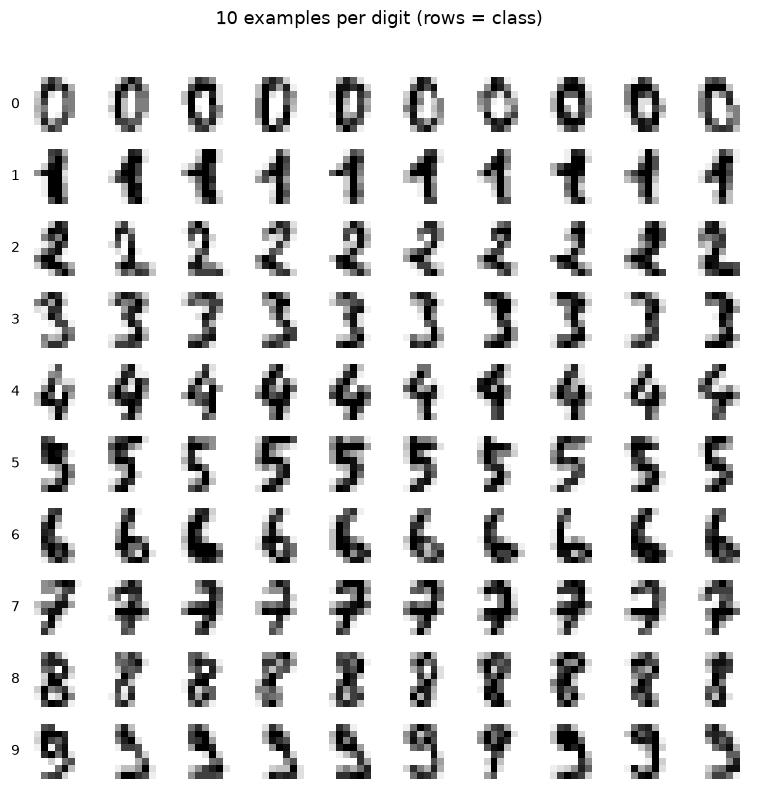

In [7]:
idx = np.concatenate([np.where(y == d)[0][:10] for d in range(10)])
show_digits(X[idx], 10, 10, row_labels=[str(d) for d in range(10)], size=0.7,
            suptitle="10 examples per digit (rows = class)")

### 1.3 Class balance, average digit, and pixel statistics
- Classes are roughly balanced, and the stratified split keeps them that way.
- The **mean image** per class shows the "template" each digit is built around.
- The pixel histogram is dominated by zeros (background). This matters for the loss: a model that outputs blank images already gets a lowish MSE. The **per-pixel variance** map shows where the useful information is: the centre of the grid. The border columns are almost always 0.

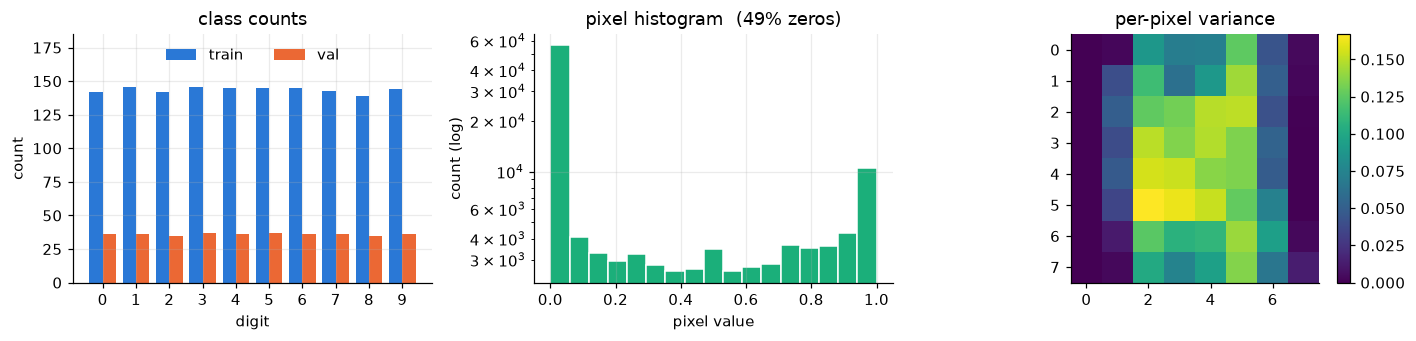

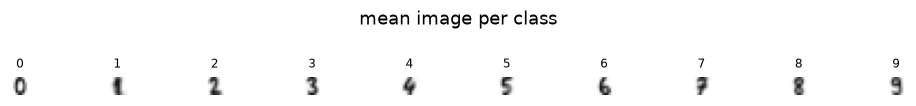

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))

counts_tr = np.bincount(y_tr, minlength=10); counts_va = np.bincount(y_va, minlength=10)
w = 0.4
axes[0].bar(np.arange(10) - w/2, counts_tr, w, label="train", color=C_AE)
axes[0].bar(np.arange(10) + w/2, counts_va, w, label="val", color=C_VAE)
axes[0].set_xticks(range(10)); axes[0].set_xlabel("digit"); axes[0].set_ylabel("count")
axes[0].set_title("class counts"); axes[0].set_ylim(0, 185)
axes[0].legend(frameon=False, ncols=2, loc="upper center")

axes[1].hist(X.flatten().numpy(), bins=17, color=C_BASE, edgecolor="white")
axes[1].set_yscale("log"); axes[1].set_xlabel("pixel value"); axes[1].set_ylabel("count (log)")
axes[1].set_title(f"pixel histogram  ({(X == 0).float().mean():.0%} zeros)")

im = axes[2].imshow(X.var(0).reshape(8, 8), cmap="viridis"); axes[2].grid(False)
axes[2].set_title("per-pixel variance"); plt.colorbar(im, ax=axes[2], fraction=0.046)
plt.tight_layout(); plt.show()

means = torch.stack([X[y == d].mean(0) for d in range(10)])
show_digits(means, 1, 10, titles=[str(d) for d in range(10)], suptitle="mean image per class")

## 2. Models

### 2.1 Autoencoder
$$x \in \mathbb R^{64} \xrightarrow{\text{encoder}} z \in \mathbb R^{8} \xrightarrow{\text{decoder}} \hat x \in [0,1]^{64}, \qquad \mathcal L_{AE} = \tfrac{1}{64}\lVert x-\hat x\rVert^2$$
The 8-unit bottleneck forces the network to compress (8 numbers instead of 64). It must learn which features matter to rebuild the image.

### 2.2 VAE
The encoder outputs the parameters of a Gaussian, $\mu(x)$ and $\log\sigma^2(x)$, rather than a single point. Training minimises the negative ELBO:
$$\mathcal L_{VAE} = \underbrace{\mathbb E_{q(z\mid x)}\big[-\log p(x\mid z)\big]}_{\text{BCE reconstruction}} + \beta\,\underbrace{\tfrac12\sum_j\big(\mu_j^2 + \sigma_j^2 - \log\sigma_j^2 - 1\big)}_{\mathrm{KL}(q(z\mid x)\,\|\,\mathcal N(0,I))}$$

**Reparameterisation trick.** Sampling $z\sim\mathcal N(\mu,\sigma^2)$ directly isn't differentiable with respect to $\mu$ and $\sigma$. Writing it as $z = \mu + \sigma\odot\varepsilon$ with $\varepsilon\sim\mathcal N(0,I)$ moves the randomness into $\varepsilon$, so gradients can flow through $\mu$ and $\sigma$. At eval time we just use $z=\mu$.

> **Fixes vs. the earlier version:** `class VAE(Autoencoder)` → `class VAE(AutoEncoder)` (name mismatch raised `NameError`), and `loss.backtward()` → `loss.backward()` in the training loop.

In [9]:
# 2. Models

## 2.1 Autoencoder
class AutoEncoder(nn.Module):
    def __init__(self, d_in=64, d_hidden=128, d_latent=8):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(d_in, d_hidden), nn.ReLU(),
            nn.Linear(d_hidden, d_latent),
        )
        self.decoder = nn.Sequential(
            nn.Linear(d_latent, d_hidden), nn.ReLU(),
            nn.Linear(d_hidden, d_in), nn.Sigmoid(), # output in [0, 1] like the input
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z

    def loss(self, x):
        x_hat, _ = self(x)
        return F.mse_loss(x_hat, x)


## 2.2 VAE
class VAE(AutoEncoder):
    """Same shape, but encoder outputs (mu, logvar) and we add a KL term."""
    def __init__(self, d_in=64, d_hidden=128, d_latent=8, beta=1.0):
        super().__init__(d_in, d_hidden, d_latent)
        self.encoder[-1] = nn.Linear(d_hidden, 2 * d_latent) # -> mu, logvar
        self.beta = beta

    def forward(self, x):
        mu, logvar = self.encoder(x).chunk(2, dim=-1)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu) if self.training else mu
        return self.decoder(z), (mu, logvar)

    def loss(self, x):
        x_hat, (mu, logvar) = self(x)
        recon = F.binary_cross_entropy(x_hat, x, reduction="sum") / len(x)
        kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / len(x)
        return recon + self.beta * kl

    @torch.inference_mode()
    def sample(self, n):
        z = torch.randn(n, self.decoder[0].in_features, device=next(self.parameters()).device)
        return self.decoder(z)

> **Note on the KL term.** The closed form is $-\tfrac12\sum(1 + \log\sigma^2 - \mu^2 - \sigma^2)$. The previous version had `mu + logvar - ...` in place of `1 + logvar - ...`. The `mu` term made the "KL" unbounded below: the optimiser could push $\mu\to+\infty$ to drive the loss down. The cell above uses the correct `1`.

### 2.3 Sanity check: shapes and parameter counts
Push one batch through each model before training and confirm the tensors have the shapes we expect.

In [10]:
xb = X_tr[:5]
for name, m in [("AutoEncoder", AutoEncoder()), ("VAE", VAE())]:
    x_hat, z = m(xb)
    n_params = sum(p.numel() for p in m.parameters())
    z_shape = tuple(z.shape) if torch.is_tensor(z) else f"mu {tuple(z[0].shape)}, logvar {tuple(z[1].shape)}"
    print(f"{name:12s} | params {n_params:6,d} | x {tuple(xb.shape)} -> z {z_shape} -> x_hat {tuple(x_hat.shape)} | initial loss {m.loss(xb).item():.4f}")

AutoEncoder  | params 18,760 | x (5, 64) -> z (5, 8) -> x_hat (5, 64) | initial loss 0.1857
VAE          | params 19,792 | x (5, 64) -> z mu (5, 8), logvar (5, 8) -> x_hat (5, 64) | initial loss 45.0299


## 3. Training

The loop is the same as before. It now also records a per-epoch **history** (mean train loss, val loss, val MSE) so we can plot learning curves, and it takes a `verbose` flag for the sweeps later on. History is stored on `model.history`, so `fit` still returns the model.

`encode` returns the latent code: $z$ for the AE, $\mu$ for the VAE.

In [11]:
# 3. Generic train loop
def fit(model, epochs=100, lr=1e-3, verbose=True, log_every=25):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    history = {"train_loss": [], "val_loss": [], "val_mse": []}
    for epoch in range(1, epochs+1):
        model.train()
        running = 0.0
        for (xb,) in train_dl:
            xb = xb.to(device)
            loss = model.loss(xb)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            running += loss.item() * len(xb)

        model.eval()
        with torch.inference_mode():
            va = sum(model.loss(xb.to(device)).item() * len(xb) for (xb,) in val_dl) / len(X_va)
            mse = F.mse_loss(model(X_va.to(device))[0], X_va.to(device)).item()
        history["train_loss"].append(running / len(X_tr))
        history["val_loss"].append(va)
        history["val_mse"].append(mse)

        if verbose and epoch % log_every == 0:
            print(f"    epoch {epoch:3d} | train loss {history['train_loss'][-1]:.4f} | val loss {va:.4f} | val MSE {mse:.4f}")

    model.history = history
    return model

@torch.inference_mode()
def encode(model, X):
    model.eval()
    out = model(X.to(device))[1]
    return (out[0] if isinstance(out, tuple) else out).cpu().numpy() # use mu for VAE

@torch.inference_mode()
def reconstruct(model, X):
    model.eval()
    return model(X.to(device))[0].cpu()

In [12]:
torch.manual_seed(SEED)
print("AutoEncoder")
ae = fit(AutoEncoder().to(device), epochs=100)

torch.manual_seed(SEED)
print("VAE")
vae = fit(VAE().to(device), epochs=100)

AutoEncoder


    epoch  25 | train loss 0.0188 | val loss 0.0198 | val MSE 0.0198


    epoch  50 | train loss 0.0147 | val loss 0.0161 | val MSE 0.0161


    epoch  75 | train loss 0.0129 | val loss 0.0145 | val MSE 0.0145


    epoch 100 | train loss 0.0116 | val loss 0.0135 | val MSE 0.0135
VAE


    epoch  25 | train loss 25.2506 | val loss 23.5452 | val MSE 0.0345


    epoch  50 | train loss 24.7158 | val loss 22.9459 | val MSE 0.0290


    epoch  75 | train loss 24.5790 | val loss 22.6976 | val MSE 0.0268


    epoch 100 | train loss 24.4978 | val loss 22.6337 | val MSE 0.0256


### 3.1 Learning curves
The AE loss (mean squared error per pixel) and the VAE loss (BCE + KL summed per image) are on **different scales**, so each gets its own panel. The third panel compares the models on a shared metric: validation MSE per pixel.

A val curve that tracks the train curve closely means little overfitting. That is expected here, since the models are small and the data is simple.

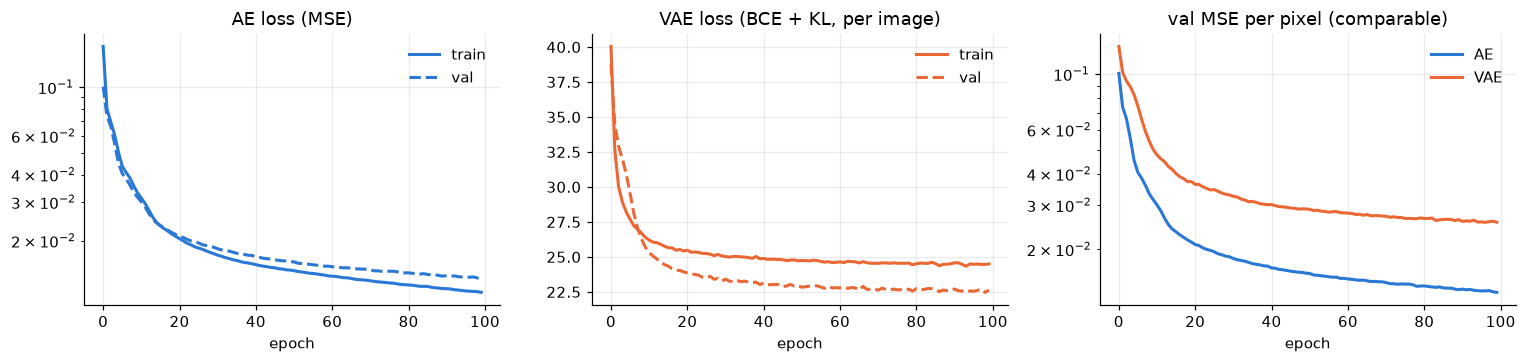

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
for ax, m, title, c in [(axes[0], ae, "AE loss (MSE)", C_AE), (axes[1], vae, "VAE loss (BCE + KL, per image)", C_VAE)]:
    ax.plot(m.history["train_loss"], color=c, label="train")
    ax.plot(m.history["val_loss"], color=c, ls="--", label="val")
    ax.set_title(title); ax.set_xlabel("epoch"); ax.legend(frameon=False)
axes[0].set_yscale("log")

axes[2].plot(ae.history["val_mse"], color=C_AE, label="AE")
axes[2].plot(vae.history["val_mse"], color=C_VAE, label="VAE")
axes[2].set_yscale("log"); axes[2].set_title("val MSE per pixel (comparable)"); axes[2].set_xlabel("epoch")
axes[2].legend(frameon=False)
plt.tight_layout(); plt.show()

### 3.2 Splitting the VAE loss into reconstruction and KL
The VAE balances two terms. Measuring each on the validation set shows how many "nats" the model spends encoding information in $z$ (the KL) compared with how much reconstruction error it accepts.

In [14]:
@torch.inference_mode()
def vae_parts(model, X):
    model.eval()
    x = X.to(device)
    x_hat, (mu, logvar) = model(x)
    recon = F.binary_cross_entropy(x_hat, x, reduction="sum").item() / len(x)
    kl_per_dim = (-0.5 * (1 + logvar - mu.pow(2) - logvar.exp())).mean(0).cpu().numpy()
    return recon, kl_per_dim

recon, kl_dim = vae_parts(vae, X_va)
print(f"val reconstruction (BCE/image): {recon:.2f}  |  val KL/image: {kl_dim.sum():.2f} nats  |  total: {recon + kl_dim.sum():.2f}")

val reconstruction (BCE/image): 19.20  |  val KL/image: 3.44 nats  |  total: 22.63


## 4. Reconstructions

### 4.1 Side by side
One validation example per digit. Row 1 is the input, row 2 the AE reconstruction, row 3 the VAE reconstruction. The VAE's reconstructions are usually a little **blurrier**: the KL term limits how much information each $z$ can carry.

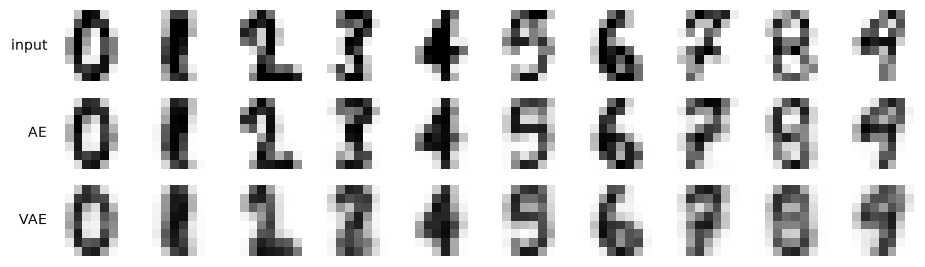

In [15]:
pick = np.array([np.where(y_va == d)[0][0] for d in range(10)])
x_in = X_va[pick]
grid = torch.cat([x_in, reconstruct(ae, x_in), reconstruct(vae, x_in)])
show_digits(grid, 3, 10, row_labels=["input", "AE", "VAE"], size=0.85)

### 4.2 Error distribution and per-class error
The average MSE hides how the errors are spread. Looking at **per-sample** and **per-class** error tells us which digits are hardest to compress. Digits with loops and closely spaced strokes (8 and 9 in this run) are the hardest. Digits with a simple, consistent shape (0, 1, 6) are the easiest.

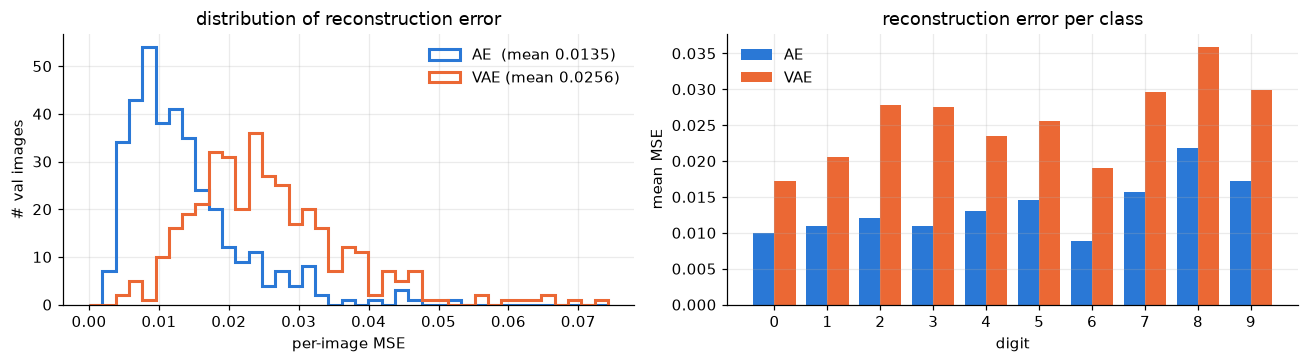

In [16]:
err_ae = ((reconstruct(ae, X_va) - X_va) ** 2).mean(1).numpy()
err_vae = ((reconstruct(vae, X_va) - X_va) ** 2).mean(1).numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
bins = np.linspace(0, max(err_ae.max(), err_vae.max()), 40)
axes[0].hist(err_ae, bins=bins, histtype="step", lw=2, color=C_AE, label=f"AE  (mean {err_ae.mean():.4f})")
axes[0].hist(err_vae, bins=bins, histtype="step", lw=2, color=C_VAE, label=f"VAE (mean {err_vae.mean():.4f})")
axes[0].set_xlabel("per-image MSE"); axes[0].set_ylabel("# val images"); axes[0].set_title("distribution of reconstruction error")
axes[0].legend(frameon=False)

per_cls_ae = [err_ae[y_va == d].mean() for d in range(10)]
per_cls_vae = [err_vae[y_va == d].mean() for d in range(10)]
w = 0.4
axes[1].bar(np.arange(10) - w/2, per_cls_ae, w, color=C_AE, label="AE")
axes[1].bar(np.arange(10) + w/2, per_cls_vae, w, color=C_VAE, label="VAE")
axes[1].set_xticks(range(10)); axes[1].set_xlabel("digit"); axes[1].set_ylabel("mean MSE")
axes[1].set_title("reconstruction error per class"); axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

### 4.3 Worst reconstructions (AE)
The failures are often unusual handwriting: thick strokes, off-centre digits, or shapes that look like another class.

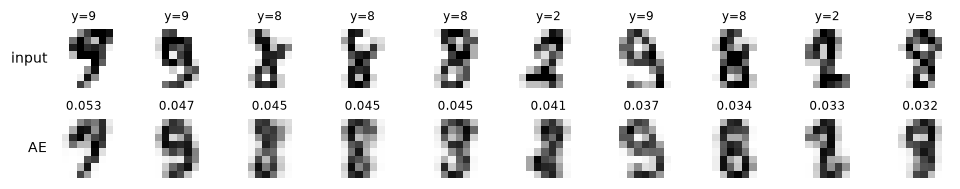

In [17]:
worst = np.argsort(-err_ae)[:10]
show_digits(torch.cat([X_va[worst], reconstruct(ae, X_va[worst])]), 2, 10,
            titles=[f"y={y_va[i]}" for i in worst] + [f"{err_ae[i]:.3f}" for i in worst],
            row_labels=["input", "AE"], size=0.9)

### 4.4 Pixel-wise error map
The mean absolute error at each pixel, averaged over the validation set. Errors concentrate where the digits vary most, matching the variance map in §1.3.

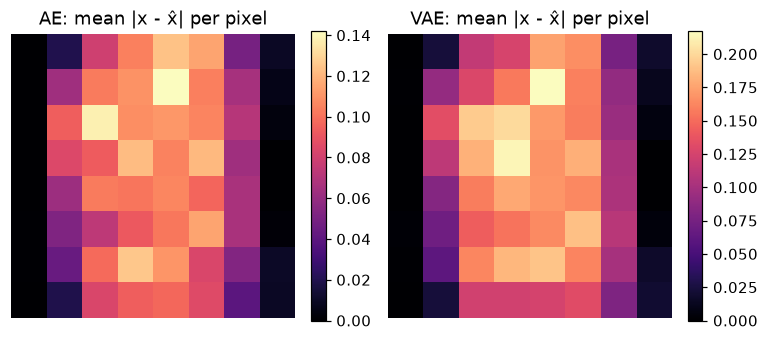

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(7, 3.2))
for ax, m, name in [(axes[0], ae, "AE"), (axes[1], vae, "VAE")]:
    im = ax.imshow((reconstruct(m, X_va) - X_va).abs().mean(0).reshape(8, 8), cmap="magma", vmin=0)
    ax.set_title(f"{name}: mean |x - x̂| per pixel"); ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

## 5. The latent space

Both models compress 64 pixels into **8 numbers**. Neither saw the labels, so if the classes still separate in latent space, the model has discovered digit identity on its own.

### 5.1 2-D projections (PCA and t-SNE)
- **PCA** is linear, so it shows the global geometry faithfully but can hide clusters.
- **t-SNE** preserves local neighbourhoods, so it shows clusters, but distances between clusters mean little.

Each digit's label is drawn at its cluster centroid, so the plot can be read without relying on colour alone.

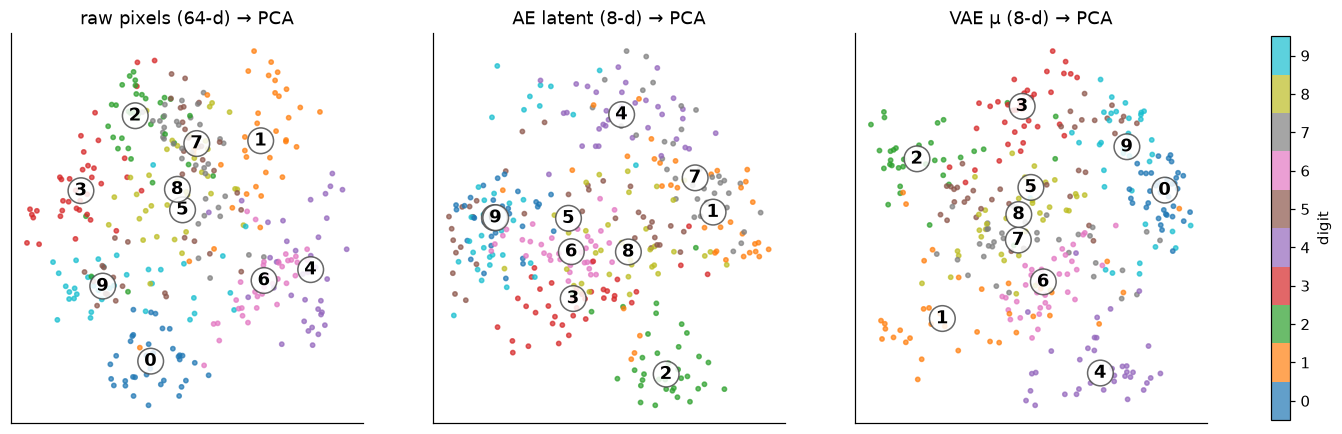

In [19]:
Z_ae_tr, Z_ae_va = encode(ae, X_tr), encode(ae, X_va)
Z_vae_tr, Z_vae_va = encode(vae, X_tr), encode(vae, X_va)

def scatter_by_digit(ax, Z2, labels, title):
    sc = ax.scatter(Z2[:, 0], Z2[:, 1], c=labels, cmap="tab10", s=8, alpha=0.7, vmin=-0.5, vmax=9.5)
    for d in range(10):
        cx, cy = np.median(Z2[labels == d], axis=0)
        ax.text(cx, cy, str(d), fontsize=12, weight="bold", ha="center", va="center",
                bbox=dict(boxstyle="circle,pad=0.2", fc="white", ec="0.3", alpha=0.85))
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
    return sc

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, Z, title in [(axes[0], X_va.numpy(), "raw pixels (64-d) → PCA"),
                     (axes[1], Z_ae_va, "AE latent (8-d) → PCA"),
                     (axes[2], Z_vae_va, "VAE μ (8-d) → PCA")]:
    sc = scatter_by_digit(ax, PCA(2, random_state=SEED).fit_transform(Z), y_va, title)
fig.colorbar(sc, ax=axes, ticks=range(10), fraction=0.015, label="digit")
plt.show()

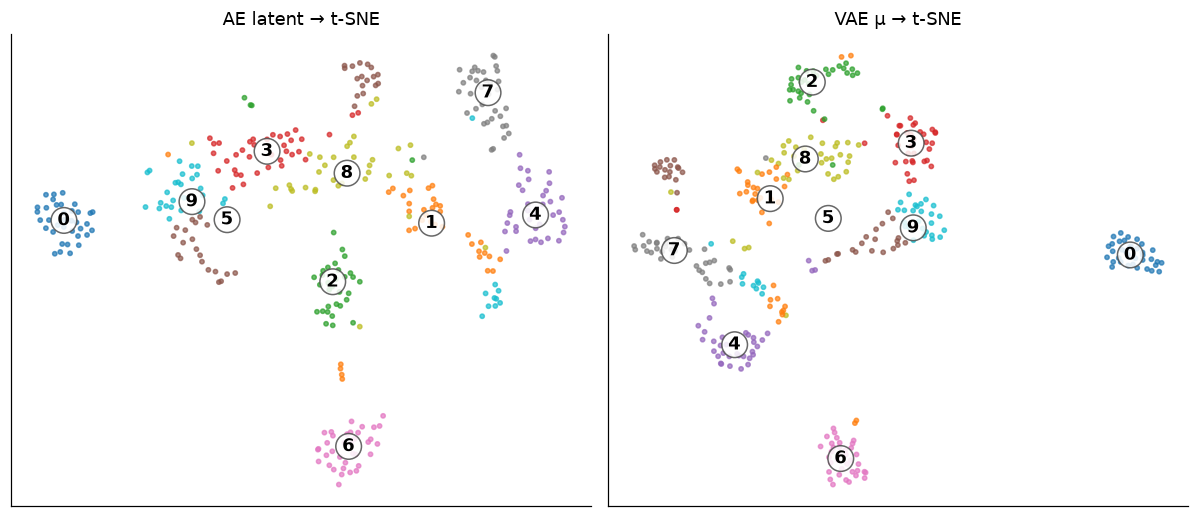

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, Z, title in [(axes[0], Z_ae_va, "AE latent → t-SNE"), (axes[1], Z_vae_va, "VAE μ → t-SNE")]:
    scatter_by_digit(ax, TSNE(2, perplexity=30, random_state=SEED, init="pca").fit_transform(Z), y_va, title)
plt.tight_layout(); plt.show()

### 5.2 Per-dimension latent statistics
This plot shows the clearest structural difference between the two models.
- **AE:** nothing constrains the scale or location of $z$. Different dimensions end up with arbitrary means and spreads.
- **VAE:** the KL term pulls the aggregate distribution of $\mu$ toward $\mathcal N(0, 1)$. Each dimension is centred near 0 with spread $\lesssim 1$.

Some VAE dimensions (narrow boxes at ≈0) are barely used. §5.3 quantifies this.

That regularity is why we can later *sample* $z\sim\mathcal N(0,I)$ for the VAE and get sensible digits.

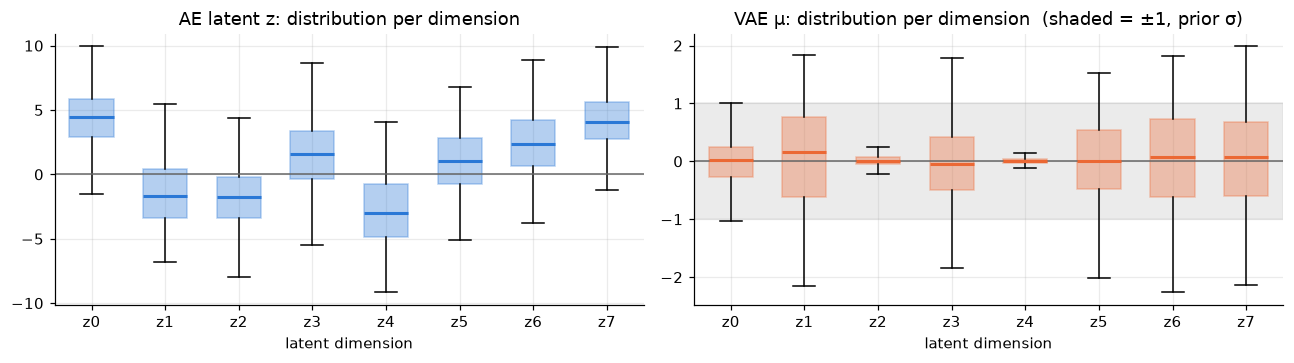

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=False)
for ax, Z, name, c in [(axes[0], Z_ae_tr, "AE latent z", C_AE), (axes[1], Z_vae_tr, "VAE μ", C_VAE)]:
    bp = ax.boxplot(Z, patch_artist=True, showfliers=False, widths=0.6)
    for box in bp["boxes"]:
        box.set(facecolor=c, alpha=0.35, edgecolor=c)
    for med in bp["medians"]:
        med.set(color=c, lw=2)
    ax.axhline(0, color="0.4", lw=1)
    ax.set_xticks(range(1, Z.shape[1] + 1)); ax.set_xticklabels([f"z{j}" for j in range(Z.shape[1])])
    ax.set_xlabel("latent dimension"); ax.set_title(f"{name}: distribution per dimension")
axes[1].axhspan(-1, 1, color="0.85", alpha=0.5, zorder=0)
axes[1].set_title("VAE μ: distribution per dimension  (shaded = ±1, prior σ)")
plt.tight_layout(); plt.show()

### 5.3 KL per latent dimension: which dimensions are in use?
A VAE dimension whose KL is ≈ 0 has posterior equal to the prior. It carries **no information** about $x$ (an "inactive" or collapsed unit). The bar chart shows how many of the 8 dimensions the VAE actually uses.

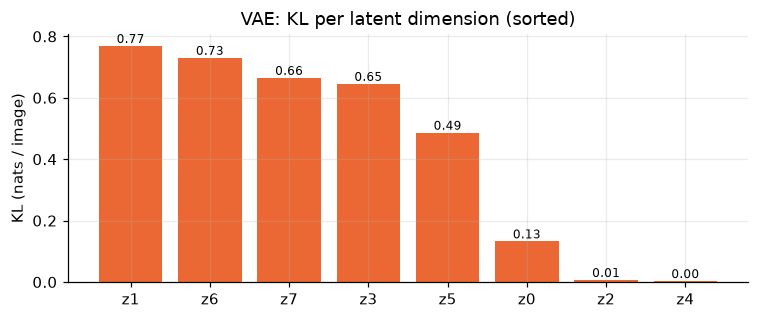

active dims (KL > 0.1 nats): 6 / 8


In [22]:
order = np.argsort(kl_dim)[::-1]
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(range(len(kl_dim)), kl_dim[order], color=C_VAE)
ax.set_xticks(range(len(kl_dim))); ax.set_xticklabels([f"z{j}" for j in order])
ax.set_ylabel("KL (nats / image)"); ax.set_title("VAE: KL per latent dimension (sorted)")
for i, v in enumerate(kl_dim[order]):
    ax.text(i, v, f"{v:.2f}", ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()
print(f"active dims (KL > 0.1 nats): {(kl_dim > 0.1).sum()} / {len(kl_dim)}")

### 5.4 What does each latent dimension do? (latent traversal)
Start from one encoded digit, vary a single latent coordinate from −3σ to +3σ while holding the others fixed, and decode. Each row is one dimension, ordered by KL (most informative first). The informative dimensions change the digit **smoothly**, for example in slant, stroke width, or a gradual change of class. The bottom rows, the dimensions with KL ≈ 0, barely change anything, which confirms that they are inactive.

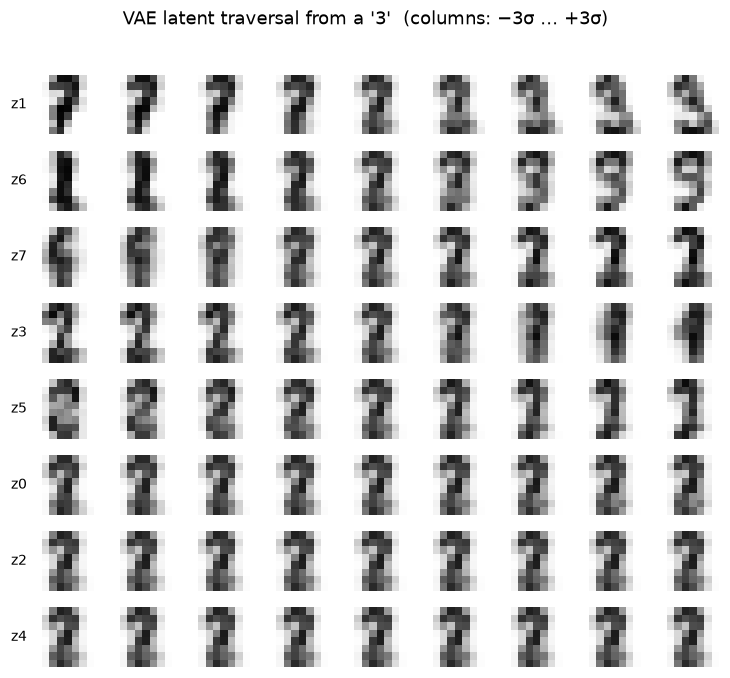

In [23]:
@torch.inference_mode()
def traverse(model, z0, Z_ref, n_steps=9, n_sd=3.0, dims=None):
    model.eval()
    dims = range(len(z0)) if dims is None else dims
    sd = Z_ref.std(0)
    rows = []
    for j in dims:
        zs = np.repeat(z0[None], n_steps, 0)
        zs[:, j] = z0[j] + np.linspace(-n_sd, n_sd, n_steps) * sd[j]
        rows.append(model.decoder(torch.tensor(zs, dtype=torch.float32, device=device)).cpu())
    return torch.cat(rows)

z0 = Z_vae_va[pick[3]]                     # an encoded "3"
dims = order                               # most-used dimensions first
show_digits(traverse(vae, z0, Z_vae_tr, dims=dims), len(dims), 9,
            row_labels=[f"z{j}" for j in dims], size=0.75,
            suptitle="VAE latent traversal from a '3'  (columns: −3σ … +3σ)")

## 6. Linear probe: is digit identity linearly readable from 8 numbers?

Freeze each representation and fit a logistic regression on the *train* codes, then score on the *val* codes. Comparison points:
- **raw pixels (64-d)**: an upper-ish reference with 8× more features
- **PCA (8-d)**: the best *linear* 8-d compression
- **AE / VAE (8-d)**: learned nonlinear compressions

A higher probe accuracy means more class information survives the bottleneck in a linearly accessible form.

raw pixels (64-d)    val accuracy = 0.975
PCA (8-d)            val accuracy = 0.919
AE (8-d)             val accuracy = 0.925
VAE μ (8-d)          val accuracy = 0.936


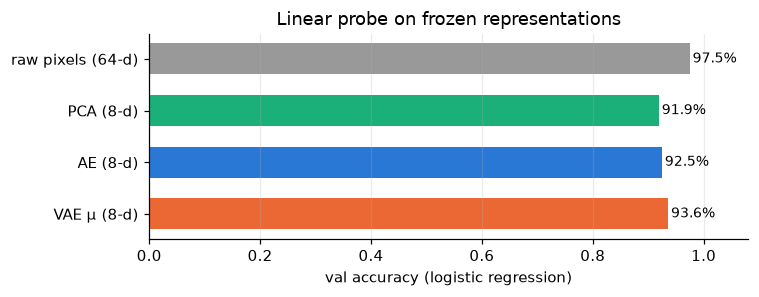

In [24]:
pca8 = PCA(8, random_state=SEED).fit(X_tr.numpy())
reps = {
    "raw pixels (64-d)": (X_tr.numpy(), X_va.numpy()),
    "PCA (8-d)":         (pca8.transform(X_tr.numpy()), pca8.transform(X_va.numpy())),
    "AE (8-d)":          (Z_ae_tr, Z_ae_va),
    "VAE μ (8-d)":       (Z_vae_tr, Z_vae_va),
}
probe_acc = {}
for name, (A_tr, A_va) in reps.items():
    clf = LogisticRegression(max_iter=5000).fit(A_tr, y_tr)
    probe_acc[name] = clf.score(A_va, y_va)
    print(f"{name:20s} val accuracy = {probe_acc[name]:.3f}")

fig, ax = plt.subplots(figsize=(7, 2.8))
names = list(probe_acc)[::-1]
colors = {"raw pixels (64-d)": "0.6", "PCA (8-d)": C_BASE, "AE (8-d)": C_AE, "VAE μ (8-d)": C_VAE}
ax.barh(names, [probe_acc[n] for n in names], color=[colors[n] for n in names], height=0.6)
for i, n in enumerate(names):
    ax.text(probe_acc[n] + 0.005, i, f"{probe_acc[n]:.1%}", va="center", fontsize=9)
ax.set_xlim(0, 1.08); ax.set_xlabel("val accuracy (logistic regression)")
ax.set_title("Linear probe on frozen representations"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## 7. Generation: decoding random latent vectors

The real test of the KL term. Draw $z\sim\mathcal N(0, I)$ and decode it.
- **VAE:** the decoder was trained on codes that look like samples from $\mathcal N(0,I)$, so most samples resemble digits.
- **AE:** $\mathcal N(0,I)$ has nothing to do with where the AE's codes actually live (see §5.2), so the decoder receives inputs it has never seen. A fairer AE baseline fits a Gaussian to the AE's training codes and samples from that. On a dataset this small and simple, that works surprisingly well. The VAE's advantage is that it gets a known sampling distribution *by construction*, with no post-hoc fitting. That difference matters more as data and latents get bigger and the code distribution gets less Gaussian.

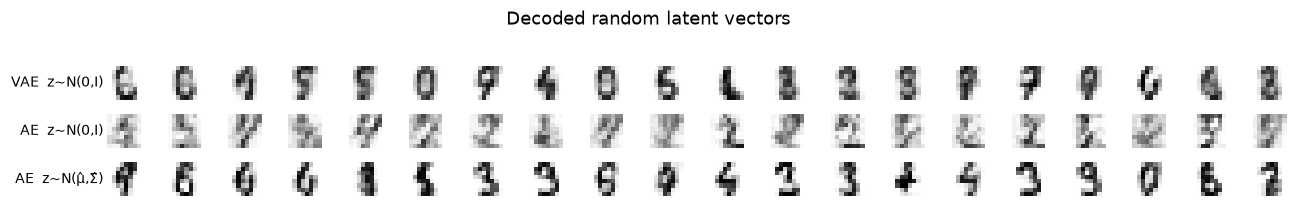

In [25]:
torch.manual_seed(SEED)
n = 20
vae_samples = vae.sample(n).cpu()

with torch.inference_mode():
    ae.eval()
    z_prior = torch.randn(n, 8, device=device)
    ae_prior = ae.decoder(z_prior).cpu()
    mu_ae, cov_ae = Z_ae_tr.mean(0), np.cov(Z_ae_tr.T)
    z_fit = torch.tensor(np.random.multivariate_normal(mu_ae, cov_ae, n), dtype=torch.float32, device=device)
    ae_fit = ae.decoder(z_fit).cpu()

show_digits(torch.cat([vae_samples, ae_prior, ae_fit]), 3, n, size=0.6,
            row_labels=["VAE  z~N(0,I)", "AE  z~N(0,I)", "AE  z~N(μ̂,Σ̂)"],
            suptitle="Decoded random latent vectors")

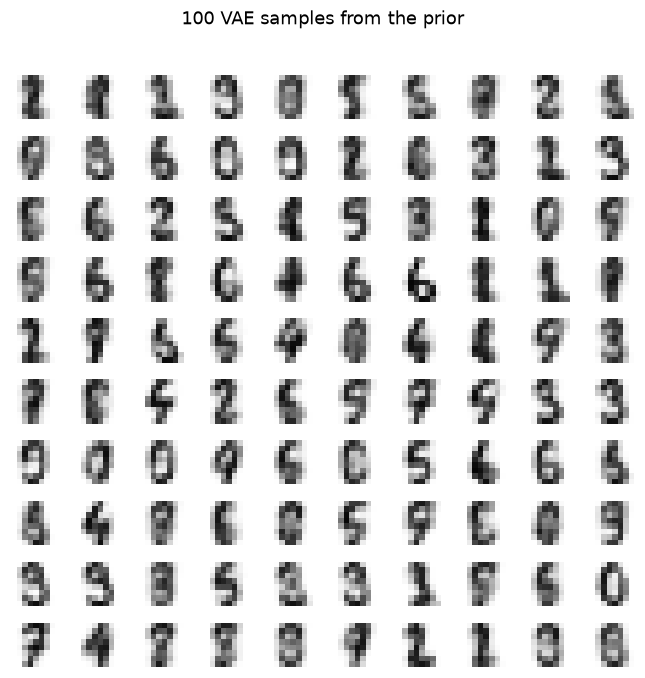

In [26]:
torch.manual_seed(0)
show_digits(vae.sample(100), 10, 10, size=0.6, suptitle="100 VAE samples from the prior")

## 8. Latent interpolation

Pick two validation digits $x_a, x_b$, encode them, and decode points along the straight line $z_t = (1-t)\,z_a + t\,z_b$.
- **Pixel space** (top row) just cross-fades the two images. The midpoints are a ghostly overlay, not a digit.
- **AE / VAE latent space:** the midpoints are decoded into digit-like shapes. The VAE path tends to be smoother because its latent space has no gaps.

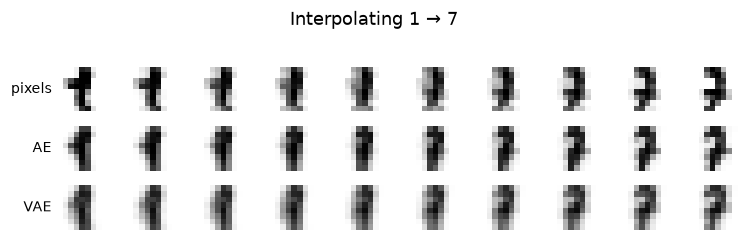

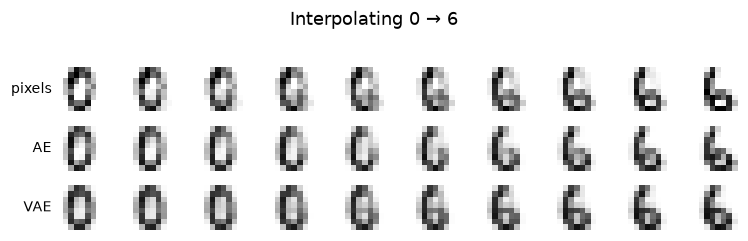

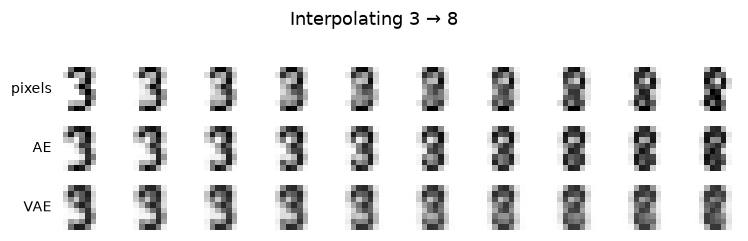

In [27]:
@torch.inference_mode()
def interpolate(model, xa, xb, steps=10):
    model.eval()
    za, zb = encode(model, xa[None])[0], encode(model, xb[None])[0]
    t = np.linspace(0, 1, steps)[:, None]
    zt = torch.tensor((1 - t) * za + t * zb, dtype=torch.float32, device=device)
    return model.decoder(zt).cpu()

for a_digit, b_digit in [(1, 7), (0, 6), (3, 8)]:
    xa = X_va[np.where(y_va == a_digit)[0][1]]
    xb = X_va[np.where(y_va == b_digit)[0][1]]
    t = torch.linspace(0, 1, 10)[:, None]
    rows = torch.cat([(1 - t) * xa + t * xb, interpolate(ae, xa, xb), interpolate(vae, xa, xb)])
    show_digits(rows, 3, 10, row_labels=["pixels", "AE", "VAE"], size=0.7,
                suptitle=f"Interpolating {a_digit} → {b_digit}")

## 9. Denoising

### 9.1 Can a plain AE clean up noise?
We add Gaussian noise and clip to $[0,1]$. A plain AE was never trained on noisy inputs, but its bottleneck partly projects inputs back toward the "digit manifold", so it removes *some* noise.

### 9.2 Denoising autoencoder (DAE)
A tiny change to the objective: corrupt the input but reconstruct the **clean** target,
$$\mathcal L_{DAE} = \lVert x - \mathrm{dec}(\mathrm{enc}(\tilde x))\rVert^2,\quad \tilde x = \mathrm{clip}(x + \sigma\varepsilon).$$
This explicitly trains the network to map noisy digits back onto clean ones. Because it is just a subclass that overrides `loss`, the same `fit` loop works unchanged.

In [28]:
def add_noise(x, sigma):
    return (x + sigma * torch.randn_like(x)).clamp(0, 1)

class DenoisingAE(AutoEncoder):
    def __init__(self, *args, noise=0.3, **kw):
        super().__init__(*args, **kw)
        self.noise = noise

    def loss(self, x):
        x_hat, _ = self(add_noise(x, self.noise) if self.training else x)
        return F.mse_loss(x_hat, x)

torch.manual_seed(SEED)
print("Denoising AE")
dae = fit(DenoisingAE(noise=0.3).to(device), epochs=100)

Denoising AE


    epoch  25 | train loss 0.0293 | val loss 0.0235 | val MSE 0.0235


    epoch  50 | train loss 0.0249 | val loss 0.0186 | val MSE 0.0186


    epoch  75 | train loss 0.0231 | val loss 0.0172 | val MSE 0.0172


    epoch 100 | train loss 0.0221 | val loss 0.0163 | val MSE 0.0163


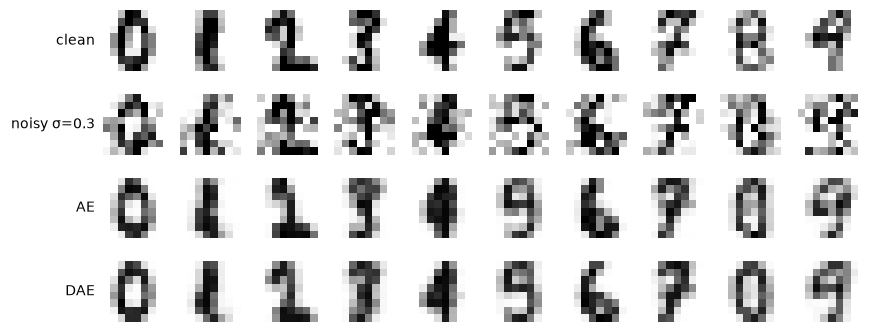

In [29]:
torch.manual_seed(1)
sigma = 0.3
x_noisy = add_noise(x_in, sigma)
show_digits(torch.cat([x_in, x_noisy, reconstruct(ae, x_noisy), reconstruct(dae, x_noisy)]), 4, 10,
            row_labels=["clean", f"noisy σ={sigma}", "AE", "DAE"], size=0.8)

### 9.3 Error vs. noise level
MSE is measured against the **clean** image. The "do nothing" baseline returns the noisy input unchanged. The DAE should stay clearly below it across a range of noise levels, including ones it was not trained at.

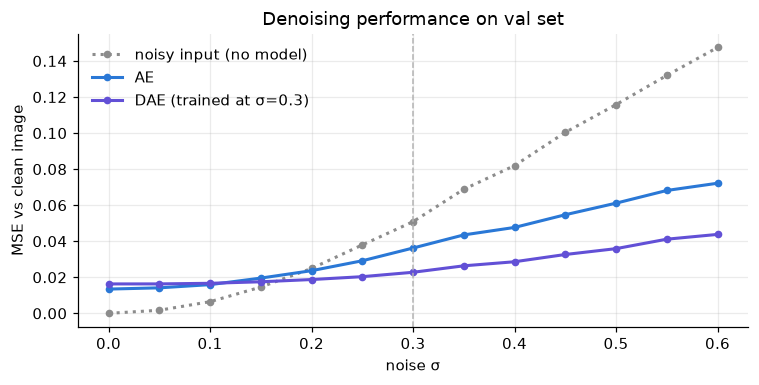

In [30]:
torch.manual_seed(2)
sigmas = np.linspace(0, 0.6, 13)
curves = {"noisy input (no model)": [], "AE": [], "DAE (trained at σ=0.3)": []}
for s in sigmas:
    xn = add_noise(X_va, s)
    curves["noisy input (no model)"].append(F.mse_loss(xn, X_va).item())
    curves["AE"].append(F.mse_loss(reconstruct(ae, xn), X_va).item())
    curves["DAE (trained at σ=0.3)"].append(F.mse_loss(reconstruct(dae, xn), X_va).item())

fig, ax = plt.subplots(figsize=(7, 3.6))
for (name, vals), c, ls in zip(curves.items(), ["0.55", C_AE, C_DAE], [":", "-", "-"]):
    ax.plot(sigmas, vals, color=c, ls=ls, marker="o", ms=4, label=name)
ax.axvline(0.3, color="0.7", lw=1, ls="--")
ax.set_xlabel("noise σ"); ax.set_ylabel("MSE vs clean image"); ax.set_title("Denoising performance on val set")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 10. How big should the latent be? AE vs PCA

Sweep the bottleneck size and compare against **PCA with the same number of components**, which is the optimal *linear* autoencoder. The gap between the two curves is what the nonlinearity buys. It is largest for small latents, where clever compression matters most.

At **k = 32** the curves cross and PCA wins. With 32 of 64 components, PCA is close to lossless (the border pixels are always 0, so the data has well under 64 effective dimensions). The AE has to *learn* a near-identity map through a ReLU network in 100 epochs and hasn't converged. Its val loss was still falling (§3.1). Nonlinear models win when compression is hard, not when it's easy.

d_latent= 1 | AE val MSE 0.0500 | PCA val MSE 0.0631


d_latent= 2 | AE val MSE 0.0392 | PCA val MSE 0.0527


d_latent= 4 | AE val MSE 0.0220 | PCA val MSE 0.0369


d_latent= 8 | AE val MSE 0.0135 | PCA val MSE 0.0240


d_latent=16 | AE val MSE 0.0070 | PCA val MSE 0.0104


d_latent=32 | AE val MSE 0.0046 | PCA val MSE 0.0023


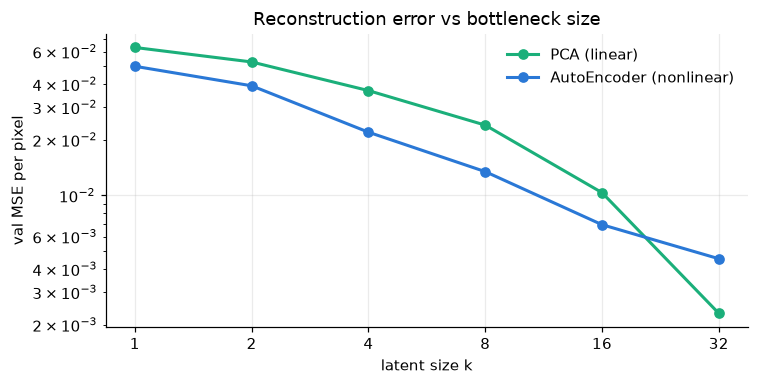

In [31]:
latent_sizes = [1, 2, 4, 8, 16, 32]
sweep_ae, sweep_pca = [], []
for k in latent_sizes:
    torch.manual_seed(SEED)
    m = fit(AutoEncoder(d_latent=k).to(device), epochs=100, verbose=False)
    sweep_ae.append(m.history["val_mse"][-1])
    p = PCA(k, random_state=SEED).fit(X_tr.numpy())
    rec = np.clip(p.inverse_transform(p.transform(X_va.numpy())), 0, 1)
    sweep_pca.append(((rec - X_va.numpy()) ** 2).mean())
    print(f"d_latent={k:2d} | AE val MSE {sweep_ae[-1]:.4f} | PCA val MSE {sweep_pca[-1]:.4f}")

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(latent_sizes, sweep_pca, marker="o", color=C_BASE, label="PCA (linear)")
ax.plot(latent_sizes, sweep_ae, marker="o", color=C_AE, label="AutoEncoder (nonlinear)")
ax.set_xscale("log", base=2); ax.set_xticks(latent_sizes); ax.set_xticklabels(latent_sizes)
ax.set_yscale("log")
ax.set_xlabel("latent size k"); ax.set_ylabel("val MSE per pixel"); ax.set_title("Reconstruction error vs bottleneck size")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 11. A 2-D VAE: seeing the whole latent manifold

With `d_latent=2` we can plot the latent space directly with no projection. We can also decode a regular grid of points to see **what the decoder has learned at every location**.

The grid uses the inverse CDF of $\mathcal N(0,1)$, so the points are spread evenly in *probability mass* under the prior rather than evenly in raw coordinates. The digits change smoothly from cell to cell, and neighbouring regions blend into one another. This continuity is what the KL term buys.

In [32]:
torch.manual_seed(SEED)
print("VAE (d_latent=2)")
vae2 = fit(VAE(d_latent=2).to(device), epochs=200, log_every=50)

VAE (d_latent=2)


    epoch  50 | train loss 24.9985 | val loss 24.0691 | val MSE 0.0426


    epoch 100 | train loss 24.6225 | val loss 23.7734 | val MSE 0.0399


    epoch 150 | train loss 24.5130 | val loss 23.6530 | val MSE 0.0380


    epoch 200 | train loss 24.3175 | val loss 23.4588 | val MSE 0.0364


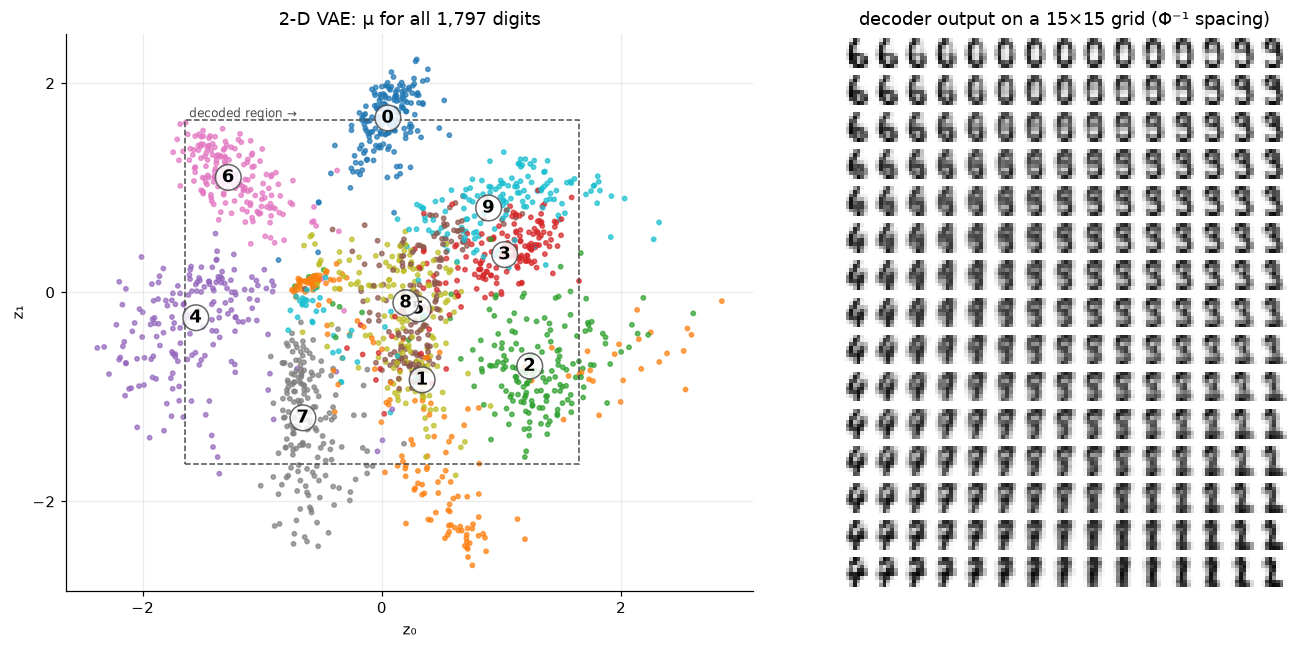

In [33]:
Z2 = encode(vae2, X)
n_grid = 15
q = torch.distributions.Normal(0, 1).icdf(torch.linspace(0.05, 0.95, n_grid))
gx, gy = torch.meshgrid(q, q.flip(0), indexing="xy")
with torch.inference_mode():
    vae2.eval()
    dec = vae2.decoder(torch.stack([gx.flatten(), gy.flatten()], 1).to(device)).cpu().numpy()
pad = 2   # blank gutter between tiles (digits fill all 8 rows, so unpadded rows fuse together)
tiles = np.pad(dec.reshape(n_grid, n_grid, 8, 8), ((0, 0), (0, 0), (pad // 2, pad - pad // 2), (0, 0)))
canvas = tiles.transpose(0, 2, 1, 3).reshape(n_grid * (8 + pad), n_grid * 8)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
scatter_by_digit(axes[0], Z2, y, "2-D VAE: μ for all 1,797 digits")
axes[0].set_xticks([-2, 0, 2]); axes[0].set_yticks([-2, 0, 2])
axes[0].set_xlabel("z₀"); axes[0].set_ylabel("z₁")
lo, hi = q[0].item(), q[-1].item()
axes[0].add_patch(plt.Rectangle((lo, lo), hi - lo, hi - lo, fill=False, ls="--", ec="0.3", lw=1))
axes[0].text(lo, hi, " decoded region →", fontsize=8, va="bottom", color="0.3")

axes[1].imshow(canvas, cmap="gray_r"); axes[1].axis("off")
axes[1].set_title(f"decoder output on a {n_grid}×{n_grid} grid (Φ⁻¹ spacing)")
plt.tight_layout(); plt.show()

## 12. Takeaways

- **Compression works.** 8 numbers reconstruct an 8×8 digit with low error. The nonlinear AE beats PCA at small and medium bottlenecks, but PCA wins once the bottleneck is wide enough to be nearly lossless (§10).
- **AE vs VAE is a trade-off.** The AE reconstructs more sharply. The VAE gives up some reconstruction quality (§4) for a **regular, continuous latent space** (§5.2, §11), which makes it a real generative model (§7) with smooth interpolations (§8).
- **Labels emerge without supervision.** A linear classifier on 8 latent numbers reaches ~92–94% accuracy against ~97.5% from all 64 pixels (§6), and t-SNE shows clean clusters (§5.1). The 8-d AE/VAE codes are only slightly better than PCA here, a reminder that this dataset is close to linearly separable.
- **Small objective changes, big effects.** The KL term turns an AE into a generator. Corrupting the input turns it into a denoiser (§9). Both are a few lines in `loss()`.

**Things to try next**
- Vary `beta` in the VAE (β-VAE). Larger β gives a smoother, more disentangled latent but blurrier reconstructions, and more dimensions collapse in §5.3.
- Swap MSE for BCE in the AE (or vice versa in the VAE) and compare §4.
- Make the encoder/decoder convolutional and run it on MNIST (28×28).

## Scratch
Small experiments kept from the earlier version.

In [34]:
a = [1, 2, 3]
a[-1] = 4
print(a)

[1, 2, 4]


In [35]:
# randn_like needs a floating-point tensor (an integer tensor raises NotImplementedError)
torch.randn_like(torch.tensor([1., 2., 3.]))

tensor([-1.8339, -1.4729, -0.1842])